In [1]:
import tensorflow as tf

In [2]:
x1=tf.constant(1)
x2=tf.constant(4)
x3= tf.add(x1,x2)
x3

<tf.Tensor: shape=(), dtype=int32, numpy=5>

In [3]:
v1=tf.constant([1,2,3,4])
v2=tf.constant([5,6,7,8])
v3= v1+v2
v3

<tf.Tensor: shape=(4,), dtype=int32, numpy=array([ 6,  8, 10, 12], dtype=int32)>

In [4]:
import pandas as pd
import numpy as np

data=pd.read_csv('FuelConsumptionCo2.csv')

In [5]:
data.head()

,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
0,2014,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,2014,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,2014,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,2014,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,2014,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


In [7]:
x_d=data.loc[:,'ENGINESIZE'].values
y_d=data.loc[:,'CO2EMISSIONS'].values

In [8]:
x=tf.constant(x_d,dtype=tf.float32)
y=tf.constant(y_d,dtype=tf.float32)

In [10]:
w=tf.Variable(2.0,dtype=tf.float32)
b=tf.Variable(7.2,dtype=tf.float32)

In [11]:
#feed forward
def H(x):
    y_pred= w*x+b
    return y_pred

In [12]:
def cost_function(y_actual,y_pred):
    mse = tf.reduce_mean(tf.square(y_actual-y_pred))
    return mse

In [13]:
lr = 0.01
epochs = 1000
losses_values = []
for epoch in range(epochs):
    with tf.GradientTape() as tape:
        y_pred = H(x)
        loss = cost_function(y,y_pred)
        losses_values.append(loss)
        gradients = tape.gradient(loss,[w,b])

        #update
        w.assign_sub(lr*gradients[0])
        b.assign_sub(lr*gradients[1])

In [15]:
import matplotlib.pyplot as plt

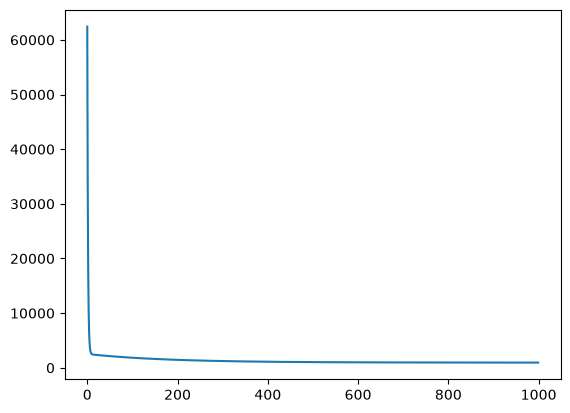

In [16]:
plt.plot(losses_values)

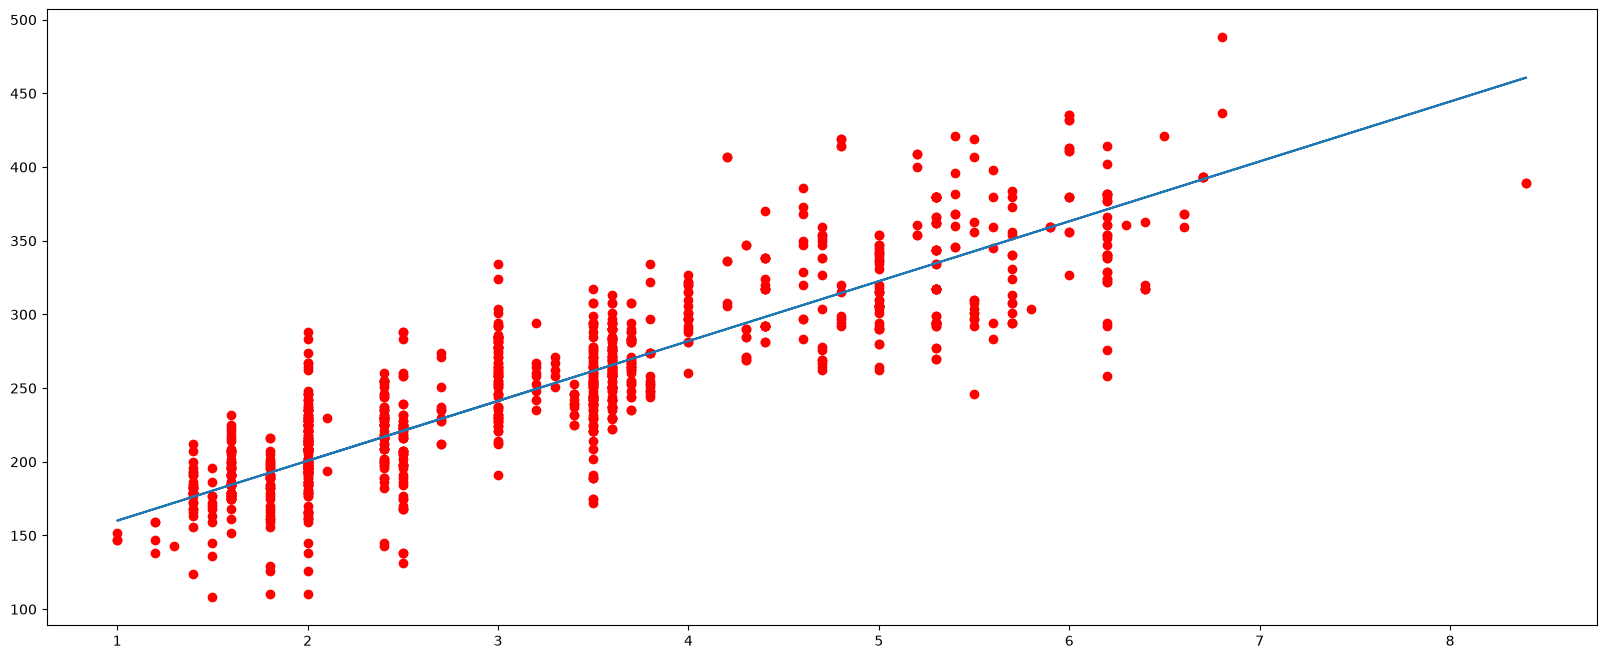

In [18]:
plt.figure(figsize=(20,8))
plt.scatter(x.numpy(),y.numpy(),c='red')
plt.plot(x.numpy(),w*x.numpy()+b)

In [19]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

model = Sequential()
model.add(Dense(2,input_dim = 1))
model.add(Dense(1))
model.summary()

c:\Users\hp\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 2)              │             4 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7 (28.00 B)

 Trainable params: 7 (28.00 B)

 Non-trainable params: 0 (0.00 B)

In [21]:
from keras.models import Model
from keras. layers import Input,Dense

visable = Input(shape=(10,))
hidden1 = Dense(500,activation='tanh')(visable)
hidden2 = Dense(300,activation='tanh')(hidden1)
hidden3 = Dense(100,activation='tanh')(hidden2)
output = Dense(1,activation='sigmoid')(hidden3)
model1 = Model(inputs=visable,outputs=output)

model1.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 500)            │         5,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 300)            │       150,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 186,001 (726.57 KB)

 Trainable params: 186,001 (726.57 KB)

 Non-trainable params: 0 (0.00 B)